# FleetRL — so sánh kết quả trước và sau sửa lỗi

**Ngày tổng hợp: 14/10/2026 (Việt Nam).**

**Kết luận chính:** các ca tái hiện cho thấy parking khi không có đơn, nút thắt sạc,
fallback và chu kỳ endpoint đã cải thiện. Hiệu năng phục vụ không tăng ở mọi nhóm;
source cuối vẫn có ca completion không đạt và thiếu telemetry timeout.

Telemetry timeout trong báo cáo này là dữ liệu ghi nhận việc bộ tối ưu có hết thời gian cho phép hay không.
Ví dụ CP-SAT được phép tính tối đa 100 ms cho một quyết định. Hệ thống cần ghi lại:
- Đã gọi solver bao nhiêu lần.
- Bao nhiêu lần solver hết thời gian.
- Tỷ lệ timeout = số lần hết thời gian / số lần gọi.

## Cách đọc

- **Trước → sau** luôn chỉ hai phiên bản trong cùng nhóm đối chứng, không phải
  một phiên bản trước chung và một phiên bản sau chung cho mọi bảng.
- Màu cam: trước sửa; xanh: sau sửa. Mỗi biểu đồ chỉ tập trung vào một câu hỏi.
- Trung bình là **trung bình các episode**, mỗi seed có trọng số bằng nhau;
  không gộp tất cả đơn vào một mẫu số. Safety là tổng số sự cố.
- KXĐ = không xác định. `null` không được đổi thành 0. Không suy timeout từ latency.
- Các bảng Markdown là snapshot tại ngày tạo; ô code đọc và vẽ lại artifact khi chạy.
  Nếu dữ liệu thay đổi, dùng script `scripts/build_fix_comparison_notebook.py`
  để cập nhật đồng thời bảng, hình và danh sách hash.
- Mở notebook để xem không cần chạy cell. Muốn chạy tương tác cần kernel Python
  có `matplotlib`; môi trường tạo file là `fleetrl-env` Python 3.12.14.
  Tại lúc tạo file, môi trường này chưa có `ipykernel`; không cài thêm dependency.

## 1. Thuật ngữ, công thức và đơn vị

| Thuật ngữ / trường dữ liệu | Nghĩa và cách đọc | Đơn vị / giới hạn |
|---|---|---|
| Episode / ca test | Một lần mô phỏng với cấu hình và seed cố định | Không đồng nghĩa một lần huấn luyện |
| Scenario / kịch bản | Cấu hình nhu cầu, đội robot, sạc, nhiễu… | S2/S4/S6 là tên cấu hình, không đủ để bảo đảm hai test tương đương |
| Tape / event tape | Chuỗi sự kiện đầu vào đã khóa, như đơn đến | Hai test ghép cặp phải dùng cùng tape |
| Seed | Số khởi tạo ngẫu nhiên để tái lập đầu vào | Cùng seed vẫn có thể khác tape khi config/source thay đổi |
| Source hash / SHA-256 | Dấu vân tay của source hoặc file bằng thuật toán băm | Định danh phiên bản; không phải điểm chất lượng |
| Checkpoint | Trọng số learner đã lưu | Giữ nguyên checkpoint khi đánh giá ảnh hưởng sửa source |
| Training seed | Seed dùng khi học ra checkpoint | Khác với tape seed dùng khi đánh giá |
| Horizon | Thời gian mô phỏng của episode | s: giây mô phỏng, không phải thời gian chờ ngoài đời |
| Completed / arrived / pending | Đơn giao xong / đơn đã đến / đơn chưa xong cuối episode | Đơn; pending không đồng nghĩa lost |
| Completion rate | completed / arrived | %; cao hơn thường tốt; không xác định nếu không có đơn |
| Deadline violation rate | deadline_violated / deadline_due | % đơn đã đến hạn nhưng trễ; mẫu số khác completion |
| Total lateness | Tổng thời gian trễ của tác vụ theo metrics simulator, gồm trễ đã phát sinh của task còn chờ | s; thấp hơn tốt, phụ thuộc horizon và workload |
| consumed_wh | Năng lượng robot thực sự tiêu thụ, gồm di chuyển và phụ tải | Wh (watt-giờ); 1 Wh = 3.600 joule; khác grid_wh lấy từ lưới |
| Energy per completed | consumed_wh / completed | Wh/đơn; không xác định khi completed = 0 |
| Auxiliary power / phụ tải | Điện cho robot hoạt động ngay cả khi đứng yên | W; W × giờ = Wh |
| Decision p95 | Phân vị 95% của thời gian quyết định: 95% mẫu không vượt mức này | ms: mili giây thực, 1.000 ms = 1 s; không phải thời gian giao hàng |
| TB p95 | Trung bình p95 của các episode | Không phải p95 của toàn bộ chu kỳ gộp chung |
| Online decision | Thời gian quyết định online được bộ runner ghi | Không trộn với thời gian inference đơn lẻ hoặc toàn episode |
| Safety incidents | Số sự cố được metrics ghi nhận, gồm vi phạm giới hạn vận hành | Sự cố; không đồng nghĩa chỉ số va chạm |
| Lost tasks | Task không còn được bảo toàn trong hệ thống | Đơn; khác pending vẫn đang được theo dõi |
| Deadlock / recovery | Robot chờ nhau không tiến triển / cơ chế giải phóng kẹt | Số lần phát hiện, xử lý, chưa xử lý; phát hiện tăng có thể là sửa được detector |
| Endpoint / lease | Điểm nhận/giao và quyền giữ điểm tạm thời | Hai owner giữ lease có thể tạo chu kỳ chờ |
| Parking / reposition | Đỗ hoặc chuyển vị trí robot khi rảnh | m: mét đường đi; chuyển động không phục vụ có thể lãng phí điện |
| ABA goal | Chuỗi mục tiêu A → B → A | Ở ca không đơn là dấu hiệu dao động; có đơn phải đọc ngữ cảnh |
| Handoff / admission | Cho phép robot đang đi đỗ hoặc hết pause nhận công việc | Pause = tạm dừng; admission = được xét làm ứng viên |
| SoC | Mức pin hiện tại / dung lượng pin | %; target 60% và 95% là mức sạc đích |
| Return calendar | Lịch cổng sạc dùng để bảo đảm robot có thể quay về sạc | Lịch kín có thể chặn ứng viên task dù pin hiện tại còn đủ |
| Fallback | Bộ điều khiển dự phòng thay hành động chính trong chu kỳ | % chu kỳ; ở đây dùng heuristic với telemetry vật lý mới |
| Telemetry / snapshot | Số đo trạng thái vật lý / ảnh chụp trạng thái ở một thời điểm | Delay 15 s = snapshot trễ 15 giây |
| Heuristic | Quy tắc điều phối thủ công, không học trọng số | Bản heuristic cũng thay đổi sau sửa sạc |
| Fixed CP-SAT | Bộ tối ưu ràng buộc với profile mục tiêu cố định | Profile 0 và 1 là cấu hình khác nhau |
| MAPPO | Multi-Agent Proximal Policy Optimization, learner đa tác tử | Trong các cặp A: checkpoint seed train 11; chưa train lại |
| DQN + CP-SAT | Deep Q-Network chọn profile cho bộ tối ưu CP-SAT | Chỉ có trong phần kiểm checkpoint mới nhất ở notebook này |
| MPC | Model Predictive Control: tối ưu theo cửa sổ dự báo | Có ở bộ 300 ca không học, không có trong bộ 360 vừa chạy |
| Gate | Ngưỡng kiểm tra đã khai báo trước chạy | Hoàn tất chạy không đồng nghĩa qua mọi gate |
| Solver timeout | Bộ tối ưu hết ngân sách thời gian | `null` = chưa xác minh; p95 thấp không chứng minh không timeout |
| Validation / holdout / OOD | Tập phát triển / tập giữ riêng / ngoài phân phối | Tập đã quan sát không còn là xác nhận hoàn toàn mới |
| Delta / điểm phần trăm | Sau − trước; 80% → 85% là +5 điểm phần trăm | Khác tăng tương đối 6,25% |
| CI95% / bootstrap | Khoảng bất định 95% ước lượng bằng lấy mẫu lại | CI chứa 0: chưa tách được khỏi 0; không chứng minh bằng nhau |

In [1]:
from pathlib import Path
from statistics import mean
import csv
import hashlib
import json
import matplotlib.pyplot as plt

candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in candidates if (p / 'runs/study14_current_source_testonly').is_dir()), None)
if ROOT is None:
    raise FileNotFoundError('Open from the FleetRL repository with its existing runs directory.')
used_files = set()

def read_json(relative: str) -> dict:
    path = ROOT / relative
    used_files.add(path)
    return json.loads(path.read_text(encoding='utf-8'))

def read_csv(relative: str) -> list[dict[str, str]]:
    path = ROOT / relative
    used_files.add(path)
    with path.open(encoding='utf-8-sig', newline='') as stream:
        return list(csv.DictReader(stream))

def aggregate(items: list[dict]) -> dict:
    result = {}
    for key in items[0]:
        values = [row.get(key) for row in items]
        if all(isinstance(v, (float, int)) for v in values):
            result[key] = sum(values) if key == 'safety_incidents' else mean(values)
        else:
            result[key] = None
    return result

BEFORE, AFTER = '#C97832', '#007F82'
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'figure.dpi': 110, 'axes.titleweight': 'bold'})

def paired_plot(records: list[dict], metric: str, title: str, unit: str,
                factor: float = 1.0) -> None:
    fig, ax = plt.subplots(figsize=(11, max(3.5, len(records) * .58)))
    positions = list(range(len(records)))
    for side, offset, color, label in [('before', -.18, BEFORE, 'Trước'),
                                       ('after', .18, AFTER, 'Sau')]:
        values = [row[side][metric] * factor for row in records]
        bars = ax.barh([v + offset for v in positions], values, height=.33,
                       color=color, label=label)
        ax.bar_label(bars, fmt='%.2f', padding=4, fontsize=9)
    ax.set_yticks(positions, [row['label'] for row in records])
    ax.invert_yaxis()
    ax.set_xlabel(unit)
    ax.set_title(title, loc='left', pad=20)
    ax.set_xlim(0, max(ax.get_xlim()[1] * 1.16, 1))
    ax.legend(loc='lower right')
    ax.grid(axis='x', alpha=.18)
    ax.set_axisbelow(True)
    fig.tight_layout()

print('Chỉ đọc artifact và tính toán thống kê; không chạy simulator hoặc test.')

Chỉ đọc artifact và tính toán thống kê; không chạy simulator hoặc test.


## 2. A — Parking/dispatch: đối chứng cùng điều kiện

Nguồn: `runs/dispatch_regression_20261013/default_validation/{baseline,conservative_handoff}/`
và `runs/dispatch_regression_20261013/protocol.json`.
Source **dddadb0… → 872ddf9…**. Đây là phiên bản sau sửa parking/dispatch,
trước các sửa sạc, pause, fallback và endpoint.

**45 cặp**: S2/S4/S6 × seed 1000–1004 × 3 controller; mỗi episode 1.200 s,
15 robot. Solver 0,1 s, decision budget 0,25 s, một worker.
Fixed dùng profile 0; heuristic threshold 0,30. MAPPO giữ checkpoint train seed 11.
Không gộp đối chứng deterministic work 0,03 vào nhóm ngân sách mặc định này.

Cấu hình đã lưu của nhóm A: S2 có nhu cầu nền 90 đơn/giờ, không burst;
S4 tăng nhu cầu gấp 2 tại vùng burst và có 40% robot khởi tạo pin thấp;
S6 có burst gấp 2, công suất cổng sạc 300 W và vị trí trạm sạc bị dịch chuyển.
W là công suất; Wh là năng lượng. Không nhầm gấp 2 ở vùng burst với gấp 2 toàn kho.
Horizon 1.200 s chỉ quan sát phần đầu burst 900–1.500 s.
Code bên dưới đối chiếu **tape, checkpoint, cấu hình chung và solver control**.
Hai trường mới `parking_min_improvement=0,02` và `parking_min_residence_s=60`
thuộc chính cơ chế sửa parking; baseline chưa có chúng. Đây là thay đổi can thiệp
được công bố, không phải thay workload hay ngân sách solver.

In [2]:
protocol = read_json('runs/dispatch_regression_20261013/protocol.json')
dispatch = []
for scenario in ['S2', 'S4', 'S6']:
    for method in ['heuristic', 'fixed_cpsat', 'mappo_dispatch']:
        samples = {'before': [], 'after': []}
        for seed in range(1000, 1005):
            prefix = 'runs/dispatch_regression_20261013/default_validation'
            name = f'{scenario}_{method}_{seed}/summary.json'
            before = read_json(f'{prefix}/baseline/{name}')
            after = read_json(f'{prefix}/conservative_handoff/{name}')
            for key in ['tape_hash', 'checkpoint_sha256', 'solver_control']:
                if before[key] != after[key]:
                    raise ValueError(f'Incomparable pair: {name}: {key}')
            changes = {k: (before['config'].get(k), after['config'].get(k))
                       for k in set(before['config']) | set(after['config'])
                       if before['config'].get(k) != after['config'].get(k)}
            expected = {'parking_min_improvement': (None, .02),
                        'parking_min_residence_s': (None, 60.0)}
            if changes != expected:
                raise ValueError(f'Unexpected configuration changes: {name}: {changes}')
            samples['before'].append(before['metrics'])
            samples['after'].append(after['metrics'])
        dispatch.append({'label': f'{scenario} / {method}', 'n': 5,
                         **{k: aggregate(v) for k, v in samples.items()}})
print('45/45 cặp khớp điều kiện; mỗi dòng tổng hợp 5 seed.')

45/45 cặp khớp điều kiện; mỗi dòng tổng hợp 5 seed.


| Nhóm | Số cặp | Hoàn thành (%) | Vi phạm hạn (%) | Tổng trễ (s) | Tiêu thụ (Wh) | Wh/đơn | p95 (ms) | Safety (tổng) |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| S2 / heuristic | 5 | 85.57 → 87.23 | 17.50 → 18.19 | 2177.19 → 2241.25 | 177.71 → 183.72 | 5.48 → 5.44 | 5.18 → 6.47 | 0.00 → 0.00 |
| S2 / fixed_cpsat | 5 | 84.71 → 89.75 | 42.61 → 32.41 | 2706.48 → 1124.22 | 365.21 → 302.53 | 11.25 → 8.72 | 49.80 → 8.68 | 0.00 → 0.00 |
| S2 / mappo_dispatch | 5 | 94.74 → 95.33 | 9.70 → 11.31 | 78.98 → 80.41 | 296.97 → 259.28 | 8.14 → 7.06 | 9.05 → 8.99 | 0.00 → 0.00 |
| S4 / heuristic | 5 | 69.89 → 69.96 | 42.00 → 41.36 | 5115.89 → 5162.60 | 156.62 → 161.69 | 6.14 → 6.33 | 5.39 → 6.36 | 0.00 → 0.00 |
| S4 / fixed_cpsat | 5 | 84.99 → 84.67 | 46.86 → 44.66 | 3037.78 → 2916.29 | 364.15 → 283.63 | 11.25 → 8.69 | 50.21 → 9.06 | 0.00 → 0.00 |
| S4 / mappo_dispatch | 5 | 93.75 → 93.30 | 14.24 → 13.33 | 136.03 → 159.18 | 303.29 → 262.13 | 8.39 → 7.28 | 8.57 → 9.06 | 0.00 → 0.00 |
| S6 / heuristic | 5 | 80.97 → 80.46 | 23.18 → 23.13 | 2164.25 → 2150.98 | 169.25 → 175.06 | 5.50 → 5.72 | 4.96 → 6.42 | 1.00 → 0.00 |
| S6 / fixed_cpsat | 5 | 75.55 → 76.09 | 60.26 → 54.33 | 6028.93 → 4106.16 | 359.13 → 278.33 | 12.39 → 9.59 | 67.33 → 10.44 | 0.00 → 0.00 |
| S6 / mappo_dispatch | 5 | 93.82 → 94.19 | 14.66 → 12.75 | 117.67 → 114.88 | 308.75 → 256.68 | 8.54 → 7.06 | 8.80 → 9.47 | 0.00 → 0.00 |

### A — Tỷ lệ hoàn thành

Fixed S2 cải thiện rõ trong lượt đo; S4 của Fixed và MAPPO giảm nhẹ. Không kết luận mọi kịch bản cùng tốt lên.

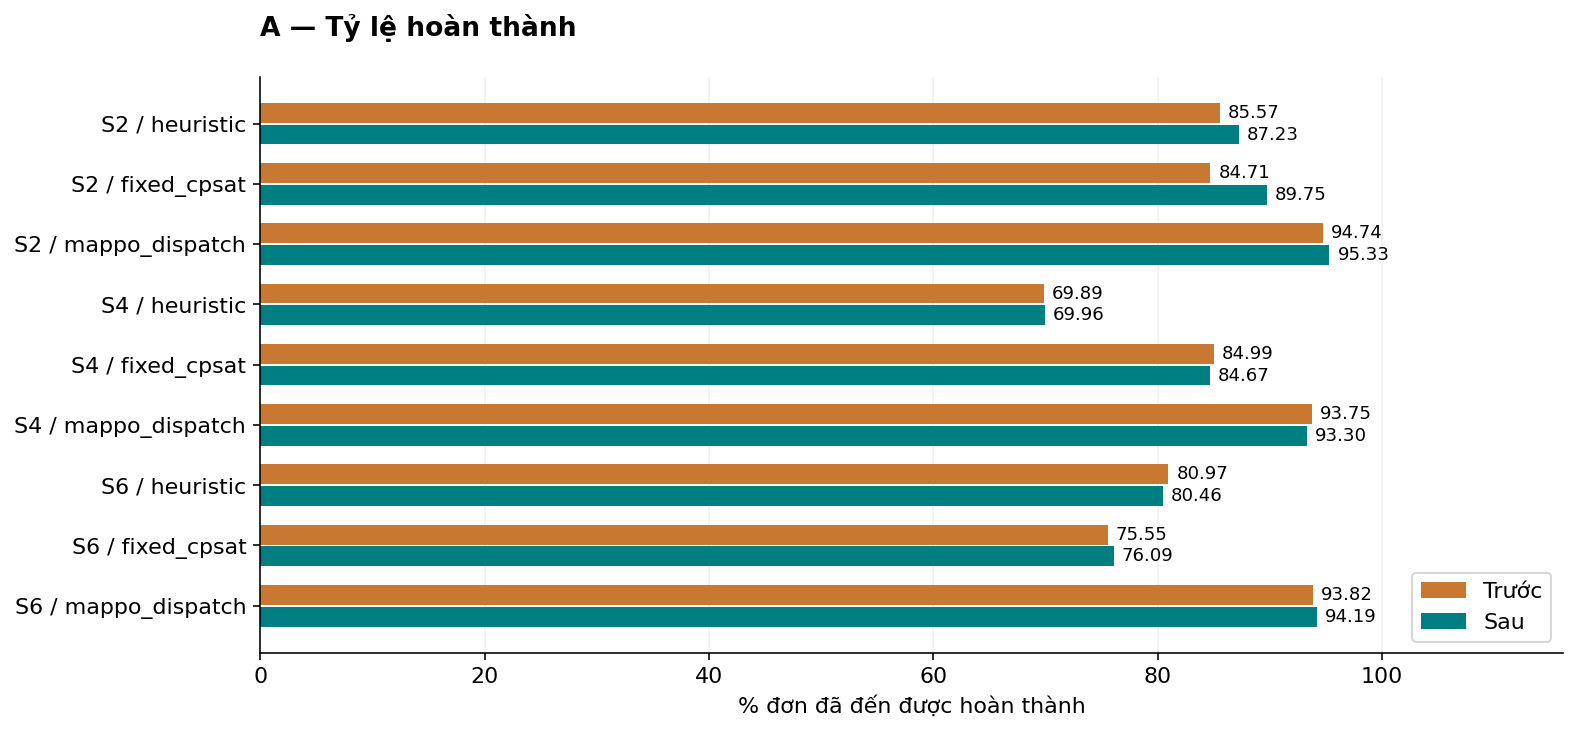

In [3]:
paired_plot(dispatch, 'completion_rate', 'A — Tỷ lệ hoàn thành', '% đơn đã đến được hoàn thành', 100)

### A — Tỷ lệ vi phạm hạn giao

Thấp hơn tốt. MAPPO S2 tăng tỷ lệ trễ dù completion tăng: hai chỉ số trả lời hai câu hỏi khác nhau và có mẫu số khác nhau.

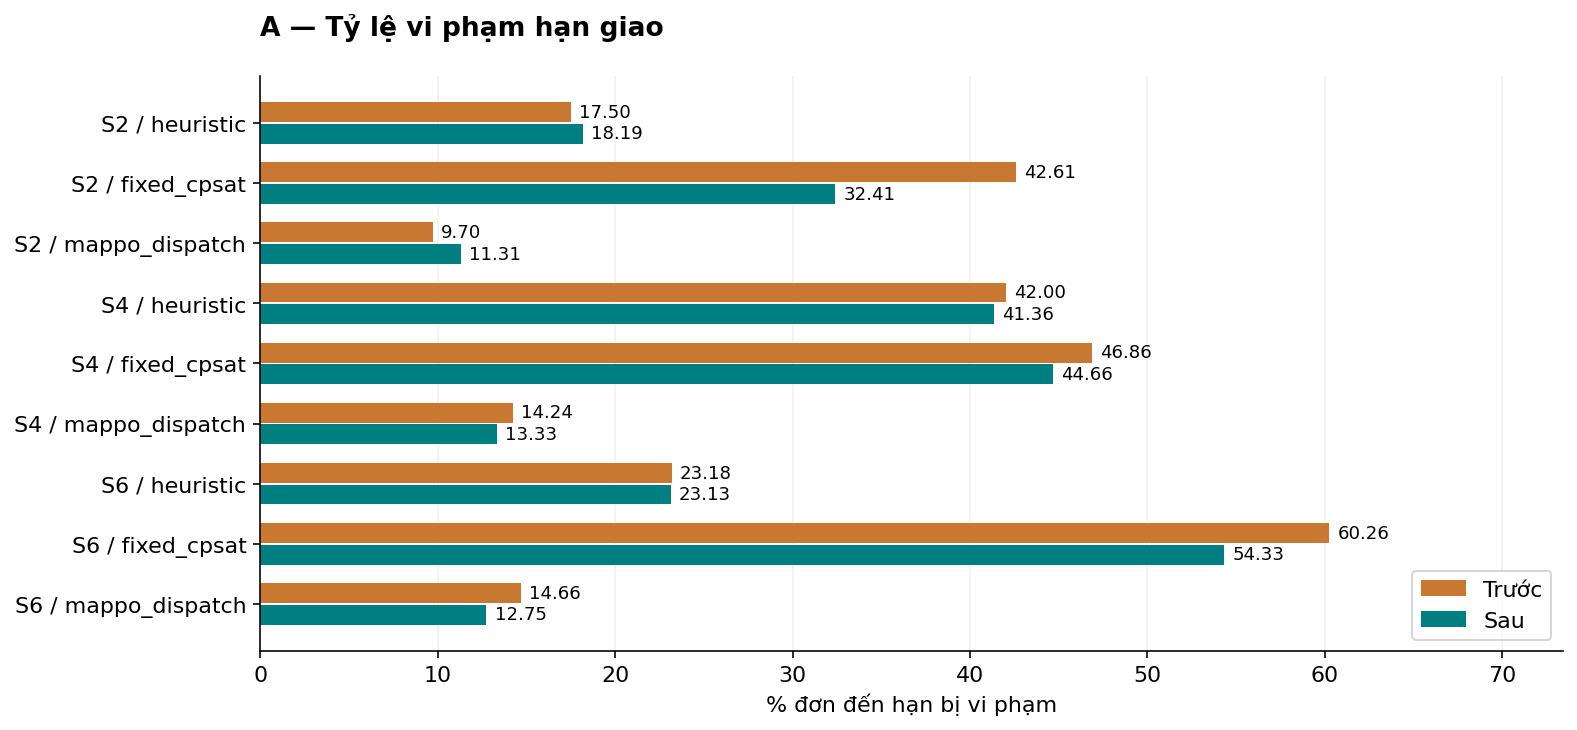

In [4]:
paired_plot(dispatch, 'deadline_violation_rate', 'A — Tỷ lệ vi phạm hạn giao', '% đơn đến hạn bị vi phạm', 100)

### A — Năng lượng toàn đội

Fixed và MAPPO giảm Wh ở cả ba kịch bản. Heuristic tăng Wh. Phải đọc cùng số đơn hoàn thành và Wh/đơn, không chỉ nhìn chiều cao cột.

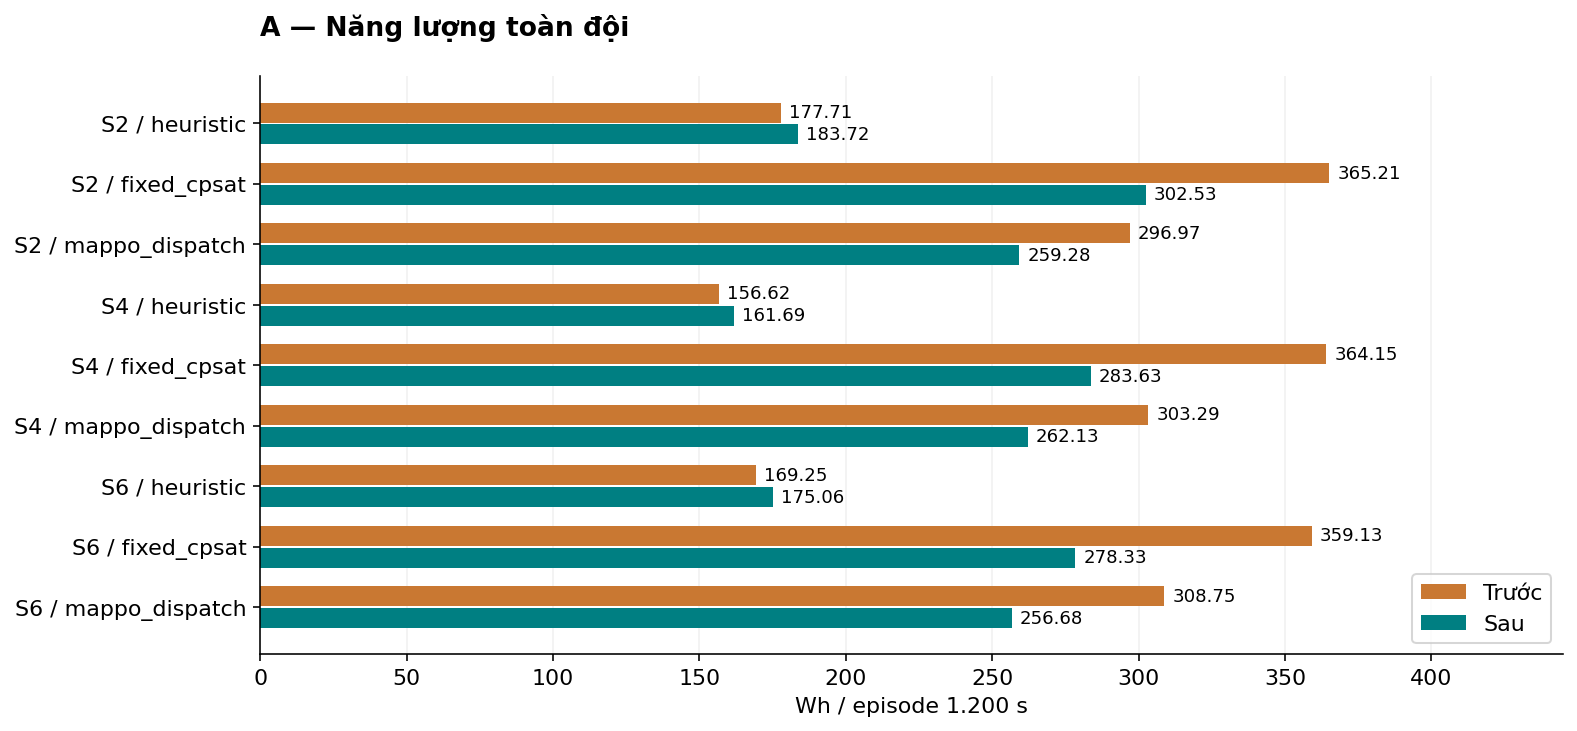

In [5]:
paired_plot(dispatch, 'consumed_wh', 'A — Năng lượng toàn đội', 'Wh / episode 1.200 s', 1)

### A — Thời gian quyết định

Đây là decision_p95_ms của runner chẩn đoán; online_decision_p95_ms không có ở nhóm này. Không gộp latency nhóm A với nhóm B–E. Wall-time chịu ảnh hưởng máy và solver cutoff; biểu đồ không phải CI tốc độ.

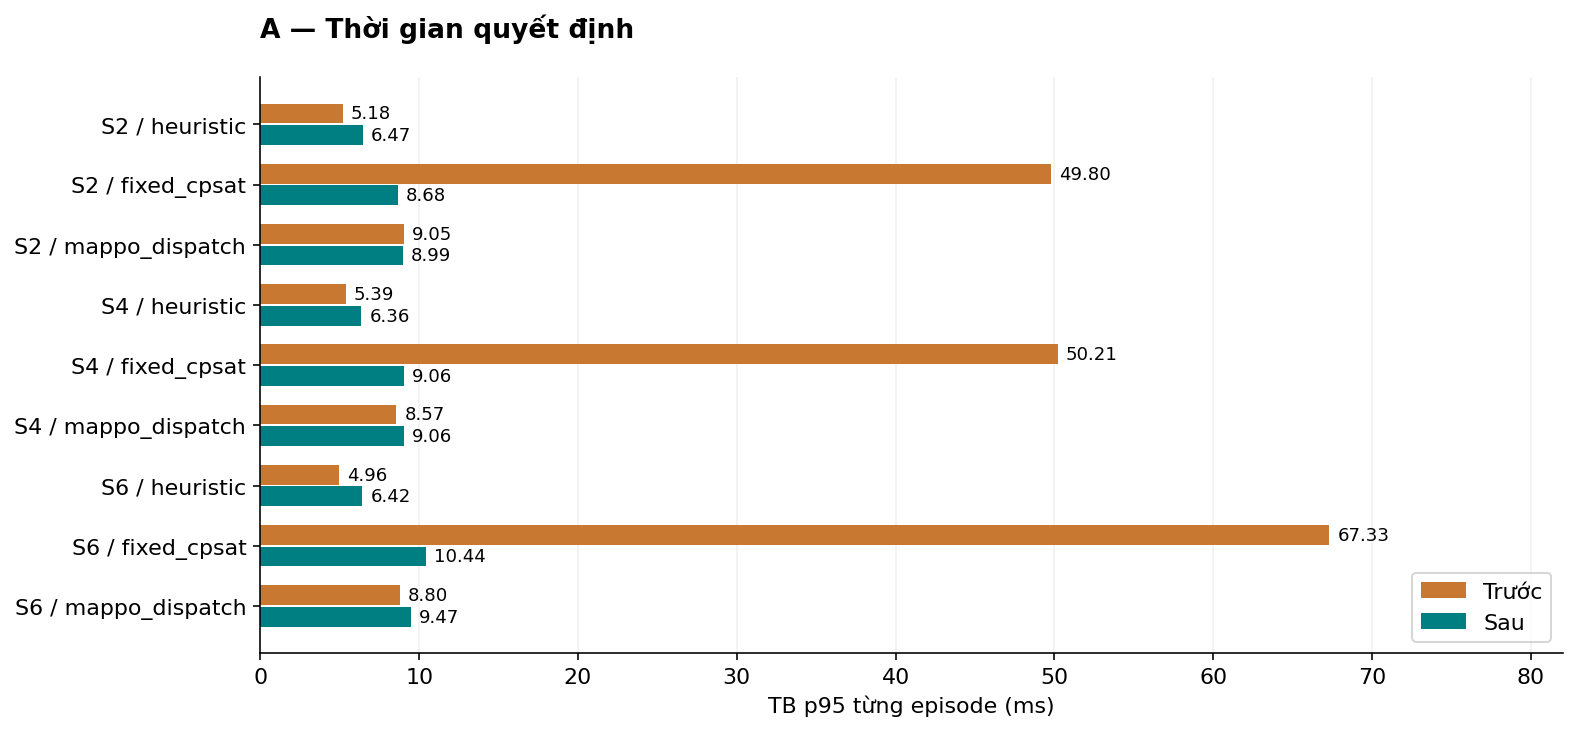

In [6]:
paired_plot(dispatch, 'decision_p95_ms', 'A — Thời gian quyết định', 'TB p95 từng episode (ms)', 1)

### A — Sự cố an toàn

S6/heuristic giảm 1 → 0 sự cố; các nhóm khác 0 → 0. Không xảy ra sự cố trong mẫu không chứng minh mọi tình huống đều an toàn.

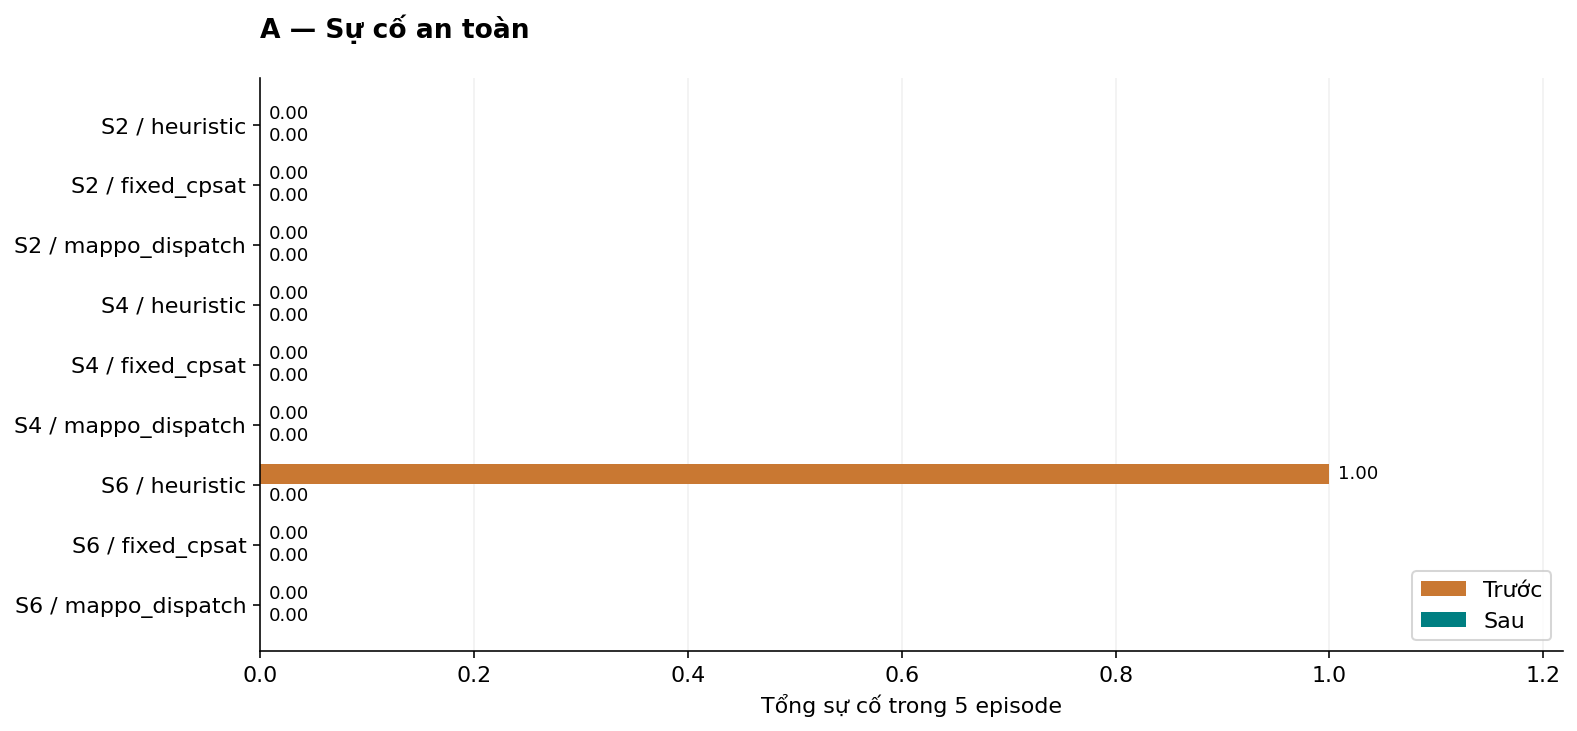

In [7]:
paired_plot(dispatch, 'safety_incidents', 'A — Sự cố an toàn', 'Tổng sự cố trong 5 episode', 1)

## 3. B–C — Sạc và dữ liệu trễ: hai ca tái hiện riêng

**B, sửa sạc:** S6/heuristic/1001, 15 robot, 1.200 s;
source 872ddf9… → 53ed06e…. Nguồn trước:
`runs/readiness_20261013/pilot/S6_replay1200_heuristic_1001/`;
sau: `runs/charging_access_20261013/partial_backlog_v2/pilot/` cùng tên ca.
Khi có backlog, heuristic dùng đích sạc thấp hơn để mở lại slot phục vụ.

**C, sửa fallback:** delay_15/heuristic/1005, 15 robot, 1.800 s;
source ed607d9… → 6a65c6e…. Nguồn trước:
`runs/readiness_pause_final_20261013/pilot/delay_15_heuristic_1005/`;
sau: `runs/stale_fallback_20261013/pilot/` cùng tên ca.
Hai nhóm đều chỉ có **1 cặp**, không phải ước lượng tổng quát trên nhiều seed.

In [8]:
def load_pair(before_dir: str, after_dir: str) -> tuple[dict, dict]:
    records = [read_json(f'{p}/metrics.json') for p in [before_dir, after_dir]]
    manifests = [read_json(f'{p}/manifest.json') for p in [before_dir, after_dir]]
    for key in ['config', 'tape_hash', 'map_hash', 'checkpoint_sha256']:
        if manifests[0].get(key) != manifests[1].get(key):
            raise ValueError(f'Incomparable pair: {before_dir}: {key}')
    return records[0]['metrics'], records[1]['metrics']

targeted = []
definitions = [
    ('B — Sạc', 'runs/readiness_20261013/pilot/S6_replay1200_heuristic_1001',
     'runs/charging_access_20261013/partial_backlog_v2/pilot/S6_replay1200_heuristic_1001'),
    ('C — Delay 15 s', 'runs/readiness_pause_final_20261013/pilot/delay_15_heuristic_1005',
     'runs/stale_fallback_20261013/pilot/delay_15_heuristic_1005'),
]
for label, before_dir, after_dir in definitions:
    before, after = load_pair(before_dir, after_dir)
    targeted.append({'label': label, 'n': 1, 'before': before, 'after': after})
print('Hai cặp khớp config, tape, map, checkpoint.')

Hai cặp khớp config, tape, map, checkpoint.


| Nhóm | Số cặp | Hoàn thành (%) | Vi phạm hạn (%) | Tổng trễ (s) | Tiêu thụ (Wh) | Wh/đơn | p95 (ms) | Safety (tổng) |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| B — Sạc | 1 | 45.95 → 86.49 | 54.55 → 45.45 | 6334.22 → 3806.35 | 116.12 → 186.37 | 6.83 → 5.82 | 17.76 → 11.14 | 0.00 → 0.00 |
| C — Delay 15 s | 1 | 12.50 → 96.88 | 86.67 → 6.67 | 39505.65 → 78.44 | 114.23 → 313.94 | 14.28 → 5.06 | 4.62 → 12.42 | 0.00 → 0.00 |

**B:** completed 17 → 32, pending 20 → 5. Tổng Wh tăng do phục vụ thêm đơn; Wh/đơn giảm 6,83 → 5,82. Trễ tổng giảm 6.334 → 3.806 s. Một ca tốt lên chưa chứng minh lịch sạc hết nút thắt.

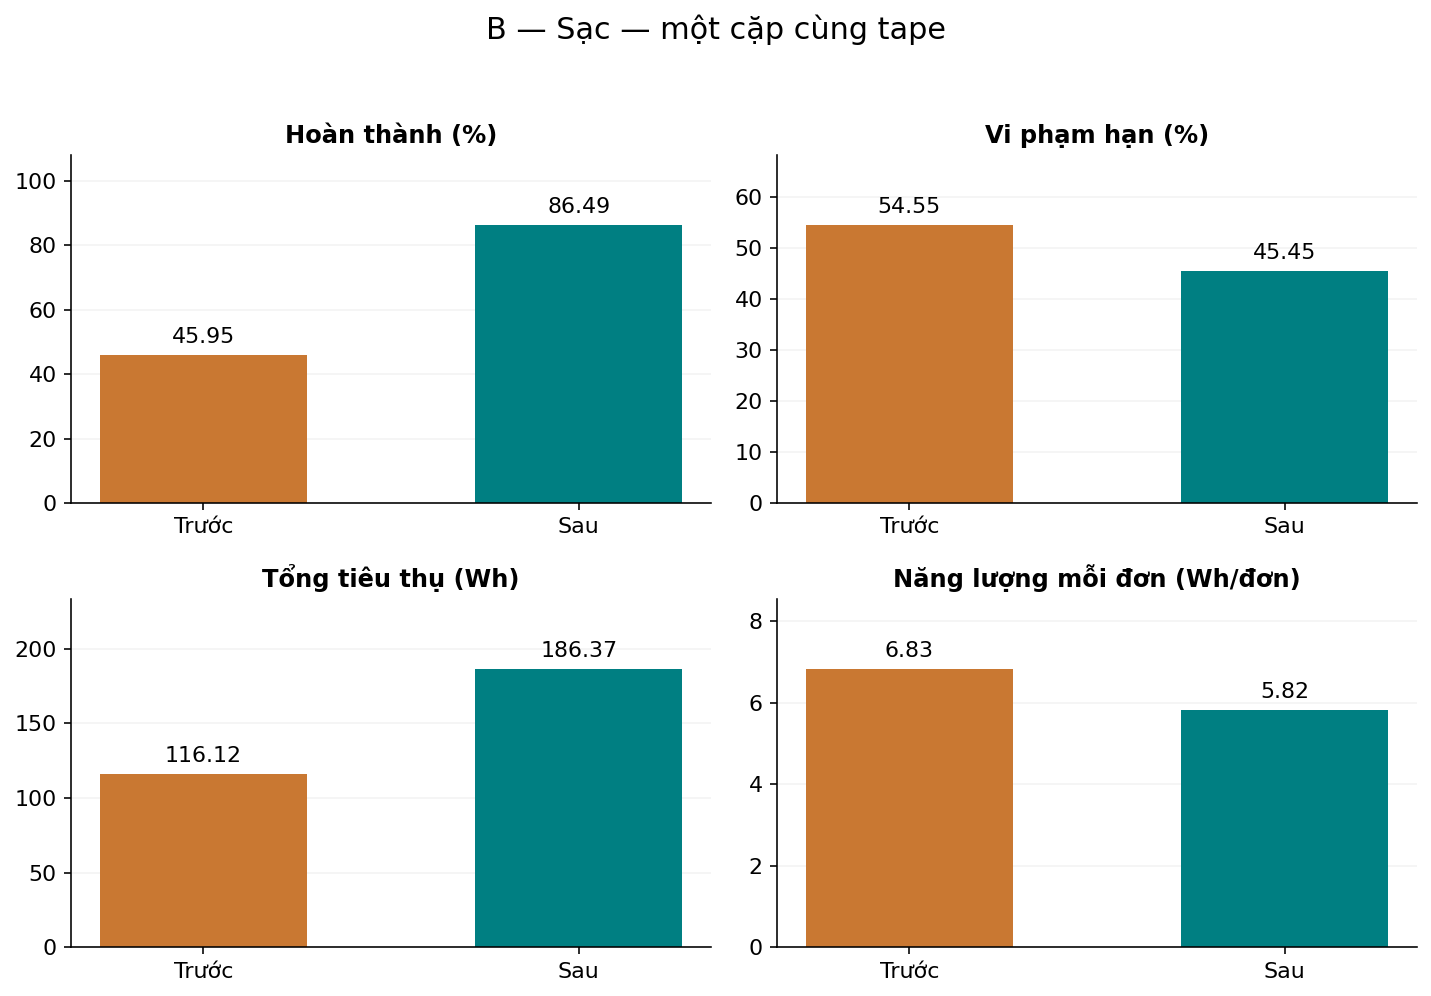

In [9]:
record = targeted[0]
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
specs = [('completion_rate', 'Hoàn thành (%)', 100),
         ('deadline_violation_rate', 'Vi phạm hạn (%)', 100),
         ('consumed_wh', 'Tổng tiêu thụ (Wh)', 1),
         ('energy_per_completed_wh', 'Năng lượng mỗi đơn (Wh/đơn)', 1)]
for ax, (metric, title, factor) in zip(axes.flat, specs):
    values = [record[side][metric] * factor for side in ['before', 'after']]
    bars = ax.bar(['Trước', 'Sau'], values, color=[BEFORE, AFTER], width=.55)
    ax.bar_label(bars, fmt='%.2f', padding=4)
    ax.set_ylim(0, max(values) * 1.25)
    ax.set_title(title, fontsize=12)
    ax.grid(axis='y', alpha=.15)
    ax.set_axisbelow(True)
fig.suptitle(record['label'] + ' — một cặp cùng tape', fontsize=15)
fig.tight_layout(rect=(0, 0, 1, .95))

**C:** completed 8 → 62, pending 56 → 2. 357/360 chu kỳ dùng heuristic fallback với telemetry vật lý hiện tại, chỉ nhận task ID đã thấy trong snapshot trễ. Không diễn giải thành hiệu năng thuần của learner hoặc khả năng chạy với toàn bộ telemetry trễ.

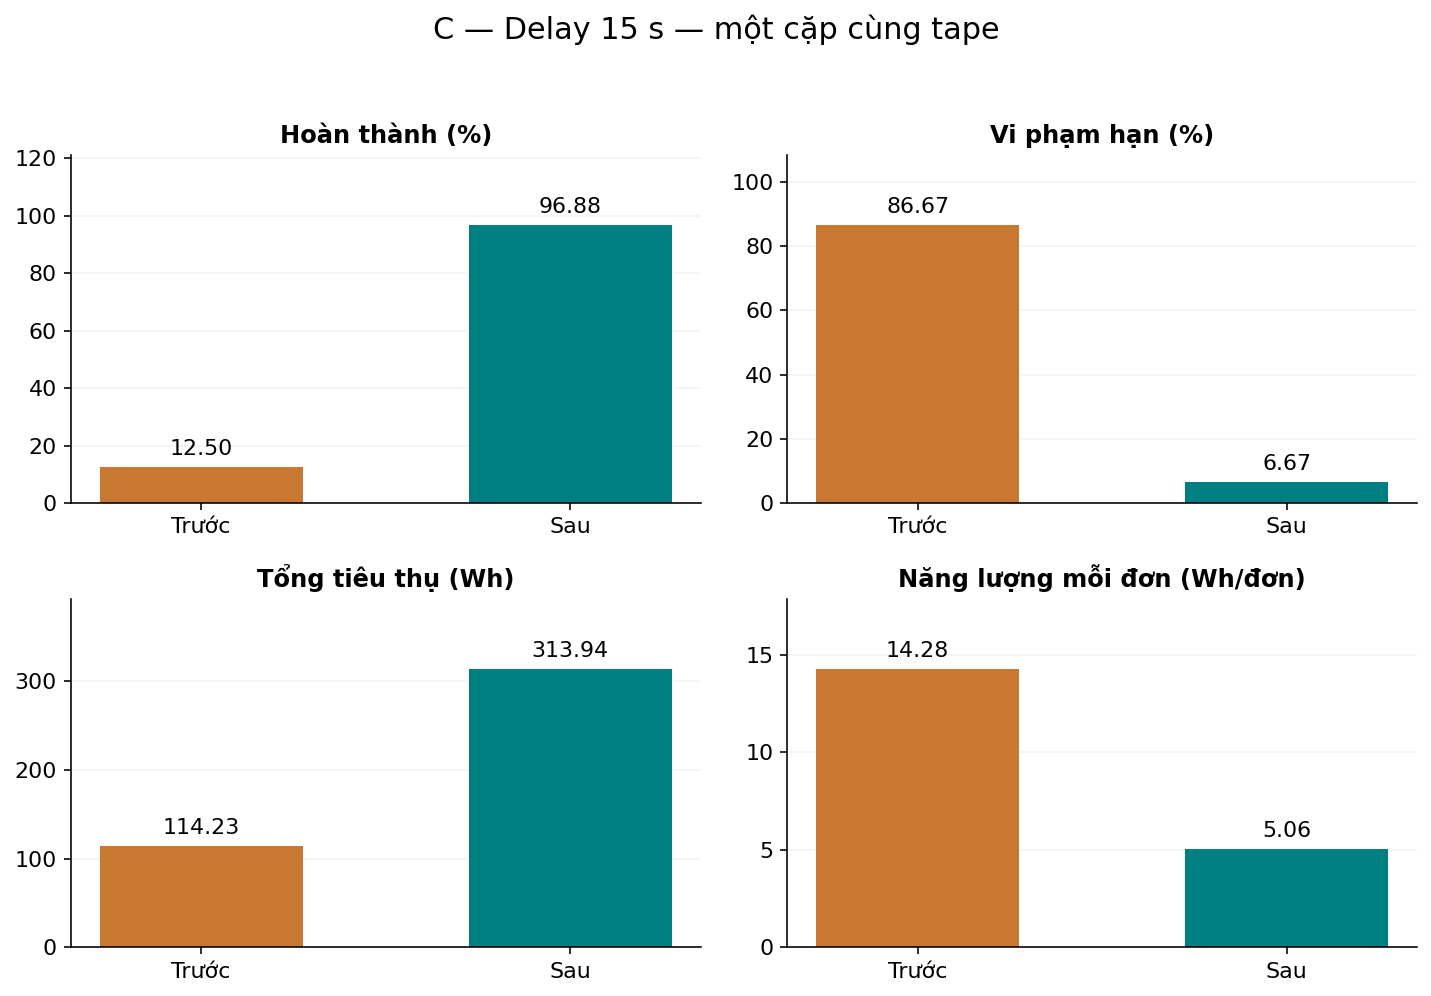

In [10]:
record = targeted[1]
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
specs = [('completion_rate', 'Hoàn thành (%)', 100),
         ('deadline_violation_rate', 'Vi phạm hạn (%)', 100),
         ('consumed_wh', 'Tổng tiêu thụ (Wh)', 1),
         ('energy_per_completed_wh', 'Năng lượng mỗi đơn (Wh/đơn)', 1)]
for ax, (metric, title, factor) in zip(axes.flat, specs):
    values = [record[side][metric] * factor for side in ['before', 'after']]
    bars = ax.bar(['Trước', 'Sau'], values, color=[BEFORE, AFTER], width=.55)
    ax.bar_label(bars, fmt='%.2f', padding=4)
    ax.set_ylim(0, max(values) * 1.25)
    ax.set_title(title, fontsize=12)
    ax.grid(axis='y', alpha=.15)
    ax.set_axisbelow(True)
fig.suptitle(record['label'] + ' — một cặp cùng tape', fontsize=15)
fig.tight_layout(rect=(0, 0, 1, .95))

## 4. D — Chu kỳ endpoint: lỗi safety tái hiện được

Nguồn `runs/endpoint_wait_validation_20261013/controlled_validation1000/`
→ `runs/endpoint_wait_fix_20261013/controlled_validation1000/`.
Source 6a65c6e… → **8bb96d9…**, 420 s, 2 robot/2 task trên map trống;
hai robot giữ lease và chờ endpoint của nhau. Đây là fixture được dựng để cô lập cơ chế lỗi.
Không suy tần suất lỗi tự nhiên từ một fixture.

Trước sửa: nhánh chờ endpoint xóa dấu thời gian bị chặn, không kích hoạt recovery;
hai lỗi route_wait_bound_exceeded xuất hiện ở 300,5 s. Sau sửa: nhận diện chu kỳ,
giữ thời gian bị chặn và recovery có kiểm tra ngân sách pin.

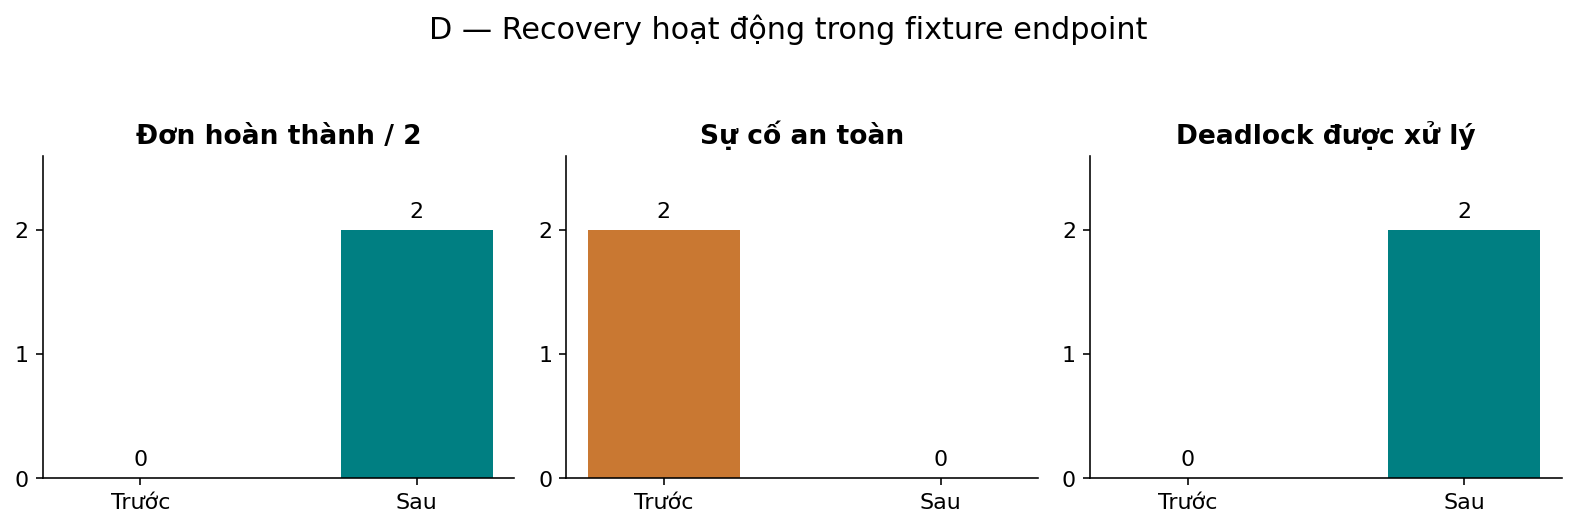

In [11]:
endpoint_fixture = []
fixture_metrics = []
for folder in ['endpoint_wait_validation_20261013', 'endpoint_wait_fix_20261013']:
    fixture_metrics.append(read_json(f'runs/{folder}/controlled_validation1000/result.json')['metrics'])
endpoint_fixture.append({'label': 'D — Endpoint fixture', 'n': 1,
                         'before': fixture_metrics[0], 'after': fixture_metrics[1]})
fig, axes = plt.subplots(1, 3, figsize=(11, 3.7))
for ax, key, title in zip(axes, ['completed', 'safety_incidents', 'deadlocks_resolved'],
                          ['Đơn hoàn thành / 2', 'Sự cố an toàn', 'Deadlock được xử lý']):
    values = [m[key] for m in fixture_metrics]
    bars = ax.bar(['Trước', 'Sau'], values, color=[BEFORE, AFTER], width=.55)
    ax.bar_label(bars, fmt='%.0f', padding=4)
    ax.set_ylim(0, 2.6)
    ax.set_yticks([0, 1, 2])
    ax.set_title(title)
fig.suptitle('D — Recovery hoạt động trong fixture endpoint', fontsize=15)
fig.tight_layout(rect=(0, 0, 1, .93))

| Nhóm | Số cặp | Hoàn thành (%) | Vi phạm hạn (%) | Tổng trễ (s) | Tiêu thụ (Wh) | Wh/đơn | p95 (ms) | Safety (tổng) |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| D — Endpoint fixture | 1 | 0.00 → 100.00 | KXĐ / không đo → KXĐ / không đo | 0.00 → 0.00 | 3.03 → 3.71 | KXĐ / không đo → 1.86 | KXĐ / không đo → KXĐ / không đo | 2.00 → 0.00 |

**Không xác định:** deadline violation vì không có task đến hạn trong 420 s;
latency vì fixture không chạy vòng controller. Tổng trễ = 0 ở cả hai phía không
có nghĩa trước sửa phục vụ tốt: trước sửa hoàn thành 0/2 đơn.
Wh tăng 3,03 → 3,71 vì sau sửa robot di chuyển và giao xong đơn.

## 5. E — S4 tự nhiên: kiểm tra hồi quy sau endpoint fix

Hai thư mục `runs/endpoint_wait_validation_20261013/pilot/`
và `runs/endpoint_wait_fix_20261013/pilot/`, S4_replay1200,
seed **1000–1019**, 1.200 s, 20 cặp mỗi controller.
Source 6a65c6e… → 8bb96d9…. Không dùng S4 cùng seed ở bộ A để thay thế:
tên và seed giống nhau chưa đủ; phải khớp tape/config.

**Cả 40 ca trước sửa không tái hiện safety failure**, nên nhóm này kiểm tra
ảnh hưởng lên hiệu năng; bằng chứng xử lý cơ chế lỗi nằm ở fixture D.

In [12]:
endpoint = []
for method in ['heuristic', 'fixed_cpsat']:
    before_items, after_items = [], []
    for seed in range(1000, 1020):
        name = f'S4_replay1200_{method}_{seed}'
        before, after = load_pair(
            f'runs/endpoint_wait_validation_20261013/pilot/{name}',
            f'runs/endpoint_wait_fix_20261013/pilot/{name}')
        before_items.append(before)
        after_items.append(after)
    endpoint.append({'label': 'E — ' + method, 'n': 20,
                     'before': aggregate(before_items), 'after': aggregate(after_items)})
intervals = read_json('runs/endpoint_wait_fix_20261013/BEFORE_AFTER_CI95.json')
print('40/40 cặp S4 khớp điều kiện. CI đọc từ artifact đã lưu, không tạo lại bootstrap.')

40/40 cặp S4 khớp điều kiện. CI đọc từ artifact đã lưu, không tạo lại bootstrap.


| Nhóm | Số cặp | Hoàn thành (%) | Vi phạm hạn (%) | Tổng trễ (s) | Tiêu thụ (Wh) | Wh/đơn | p95 (ms) | Safety (tổng) |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| E — heuristic | 20 | 93.76 → 93.76 | 10.86 → 10.86 | 877.85 → 877.85 | 200.33 → 200.33 | 5.41 → 5.41 | 6.38 → 6.23 | 0.00 → 0.00 |
| E — fixed_cpsat | 20 | 93.61 → 92.63 | 20.40 → 20.67 | 813.90 → 999.97 | 304.88 → 301.62 | 8.26 → 8.26 | 8.57 → 8.39 | 0.00 → 0.00 |

### E — Điểm phần trăm (sau − trước)

Fixed giảm khoảng 0,98 điểm phần trăm; CI chứa 0. Không kết luận hai phiên bản bằng nhau.

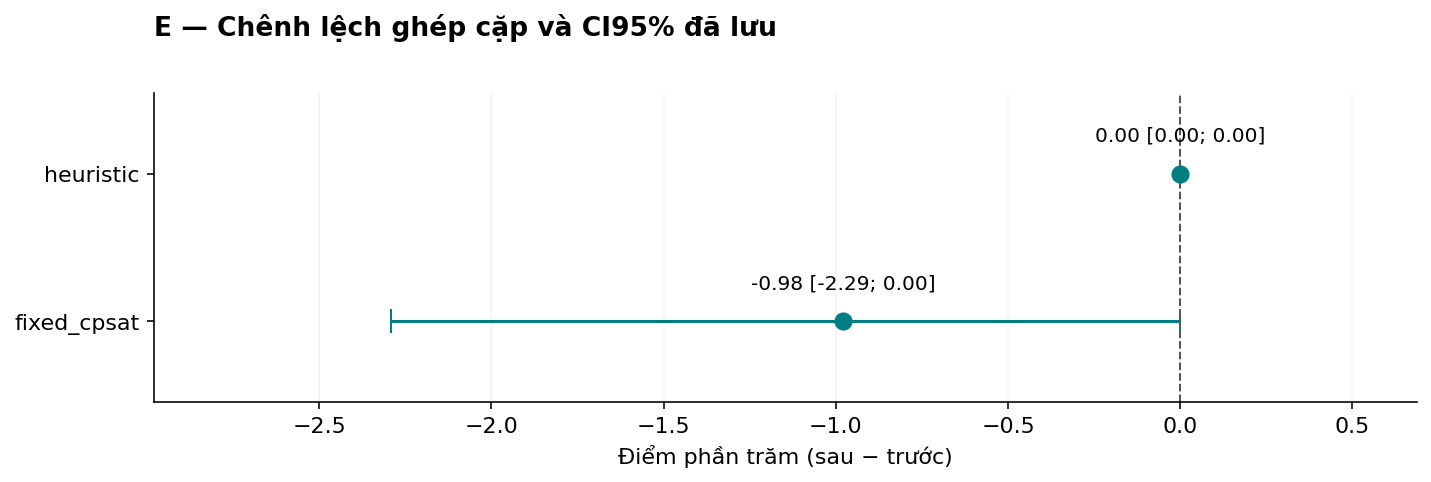

In [13]:
selected = [r for r in intervals if r['metric'] == 'completion_rate']
fig, ax = plt.subplots(figsize=(10, 3.5))
for position, item in enumerate(selected):
    center = item['mean_delta'] * 100
    low, high = item['ci95_low'] * 100, item['ci95_high'] * 100
    ax.errorbar(center, position, xerr=[[max(0, center-low)], [max(0, high-center)]],
                fmt='o', capsize=6, color=AFTER, markersize=8)
    ax.annotate(f'{center:.2f} [{low:.2f}; {high:.2f}]',
                (center, position), xytext=(0, 16), textcoords='offset points',
                ha='center', fontsize=10)
ax.set_yticks(range(len(selected)), [r['method'] for r in selected])
ax.set_ylim(-.55, len(selected)-.45)
ax.axvline(0, color='#555555', linestyle='--', linewidth=1)
ax.margins(x=.3)
ax.set_xlabel('Điểm phần trăm (sau − trước)')
ax.set_title('E — Chênh lệch ghép cặp và CI95% đã lưu', loc='left', pad=28)
ax.grid(axis='x', alpha=.15)
fig.tight_layout()

### E — Giây trễ (sau − trước)

Fixed tăng 186,07 s trễ/episode; CI95% [6,07; 401,95] không chứa 0. Đây là dấu hiệu hồi quy trong mẫu, chưa xác nhận nguyên nhân riêng là endpoint fix; solver wall-time có thể thay đổi nghiệm. Heuristic giữ nguyên KPI phục vụ.

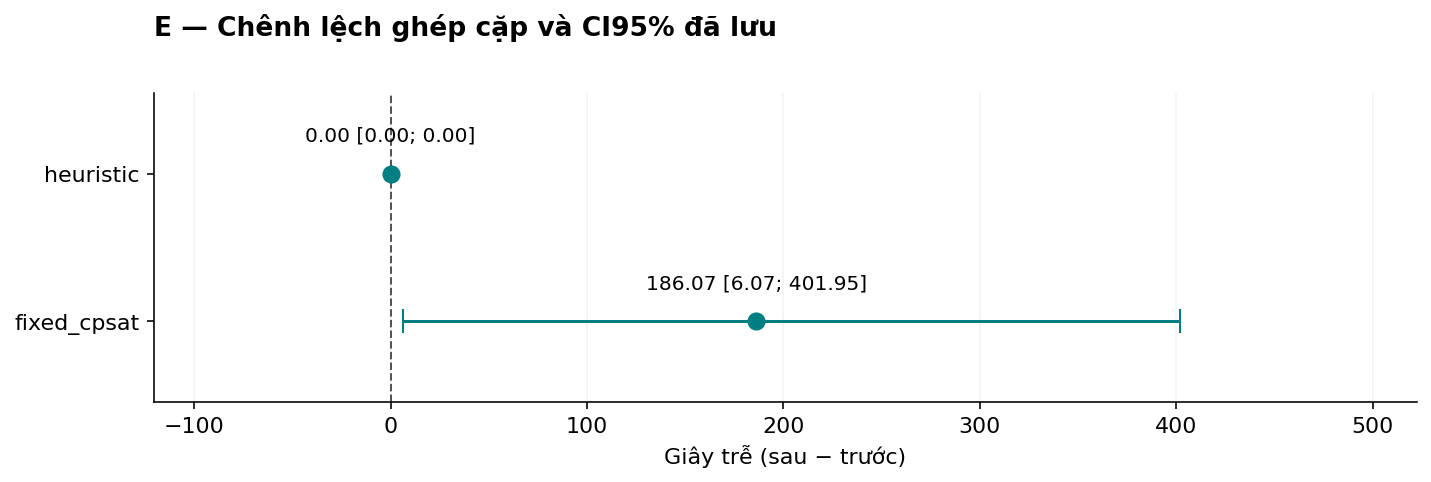

In [14]:
selected = [r for r in intervals if r['metric'] == 'total_lateness_s']
fig, ax = plt.subplots(figsize=(10, 3.5))
for position, item in enumerate(selected):
    center = item['mean_delta'] * 1
    low, high = item['ci95_low'] * 1, item['ci95_high'] * 1
    ax.errorbar(center, position, xerr=[[max(0, center-low)], [max(0, high-center)]],
                fmt='o', capsize=6, color=AFTER, markersize=8)
    ax.annotate(f'{center:.2f} [{low:.2f}; {high:.2f}]',
                (center, position), xytext=(0, 16), textcoords='offset points',
                ha='center', fontsize=10)
ax.set_yticks(range(len(selected)), [r['method'] for r in selected])
ax.set_ylim(-.55, len(selected)-.45)
ax.axvline(0, color='#555555', linestyle='--', linewidth=1)
ax.margins(x=.3)
ax.set_xlabel('Giây trễ (sau − trước)')
ax.set_title('E — Chênh lệch ghép cặp và CI95% đã lưu', loc='left', pad=28)
ax.grid(axis='x', alpha=.15)
fig.tight_layout()

## 6. Parking khi không có đơn: kiểm chứng cơ chế

Nguồn bảng trong `runs/idle_parking_20261013/REPORT.md`, mục 4.
Source dddadb0… → 744de7e…; **10 robot, 600 s, SoC đầu 99%, không nhiễu**.
Số liệu dưới đây được chép từ bảng report, không tái dựng từ trace.
Không có đơn nên completion và Wh/đơn không áp dụng.

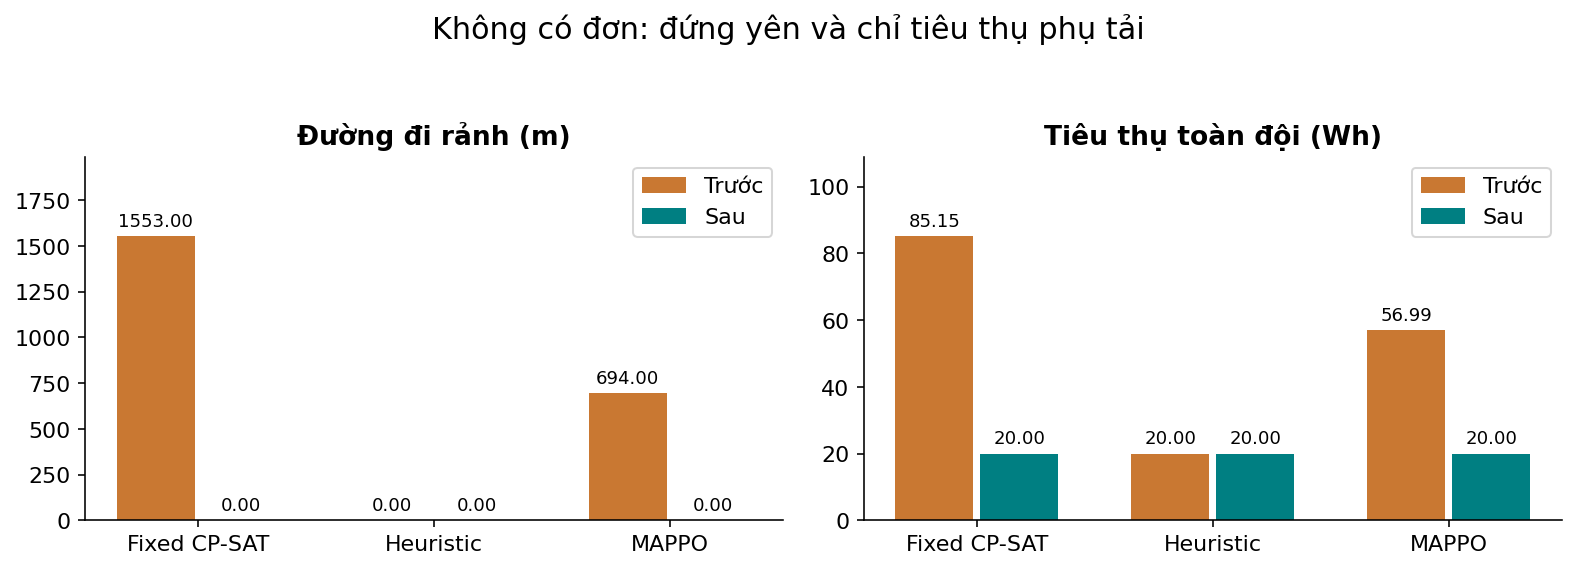

In [15]:
parking_report = ROOT / 'runs/idle_parking_20261013/REPORT.md'
used_files.add(parking_report)
if not parking_report.is_file():
    raise FileNotFoundError(parking_report)
labels = ['Fixed CP-SAT', 'Heuristic', 'MAPPO']
idle_before, idle_after = [1553, 0, 694], [0, 0, 0]
energy_before, energy_after = [85.15, 20, 56.99], [20, 20, 20]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, before, after, title in zip(axes, [idle_before, energy_before],
                                    [idle_after, energy_after],
                                    ['Đường đi rảnh (m)', 'Tiêu thụ toàn đội (Wh)']):
    for values, offset, color, label in [(before, -.18, BEFORE, 'Trước'),
                                        (after, .18, AFTER, 'Sau')]:
        bars = ax.bar([i+offset for i in range(3)], values, width=.33, color=color, label=label)
        ax.bar_label(bars, fmt='%.2f', padding=3, fontsize=9)
    ax.set_xticks(range(3), labels)
    ax.set_ylim(0, max(before+after) * 1.28)
    ax.set_title(title)
    ax.legend()
fig.suptitle('Không có đơn: đứng yên và chỉ tiêu thụ phụ tải', fontsize=15)
fig.tight_layout(rect=(0, 0, 1, .93))

**20 Wh = 10 robot × 12 W × (600 / 3.600) giờ**. Đây là điện phụ tải kỳ vọng,
không phải bằng 0. ABA goal của Fixed 822 → 0, MAPPO 233 → 0.
Khi có đơn thưa, heuristic có thể tăng di chuyển về bay; không ngoại suy ca zero
thành giảm năng lượng trong mọi workload. Bản parking đầu cũng từng tăng pending;
các sửa dispatch tiếp theo được kiểm trong nhóm A.

## 7. Những dữ liệu không tương đương và chỉ số còn thiếu

| Bộ dữ liệu | Điều kiện khác / dữ liệu thiếu | Kết luận được phép |
|---|---|---|
| Study14 gốc và lượt 360 mới | Seed 2000–2004 so với 3005–3009; 14 so với 4 phương pháp; bộ gốc có OOD_A/OOD_B, bộ mới chỉ S1–S9 | Không tính delta để quy cho sửa lỗi |
| 300 ca không học và 360 checkpoint transfer | Cùng source 8bb96d9…, nhưng khác horizon, stress fixture và controller | 360 hoàn tất không xóa ca âm trong 300 |
| Sửa pause | Sau sửa ba controller nhận task t=5 s, hoàn thành 1/1; thiếu đủ metrics trước tương ứng cho cả ba | Xác nhận hành vi sau sửa, không dựng delta KPI đầy đủ |
| Solver timeout | Nhiều trường null, gồm CP-SAT/MPC và DQN | Chưa xác minh, không thay bằng 0 |
| Fixture endpoint | Không có task đến hạn; không vòng quyết định | Deadline violation và latency không xác định/không đo |
| Zero-demand | Không có đơn đến/hoàn thành | Không định nghĩa completion và Wh/đơn |
| MAPPO/DQN checkpoint cũ | Chưa train trên dynamics mới; một số chu kỳ dùng fallback | Chỉ chứng minh khả năng chuyển source trong tập đã đo |

Nguồn: `runs/study14/plan.json`, `runs/study14/source_migration.json`,
`runs/study14_current_source_testonly/identity.json`,
`runs/readiness_nonlearning_fresh_20261013/FINAL_REPORT.md`,
`runs/paused_candidate_20261013/FIX_VERIFICATION.json`.
Study14 còn có migration source trong quá trình train; không coi tất cả checkpoint
lịch sử là được học trên cùng source duy nhất.

## 8. Lượt 360 mới nhất — chỉ là mốc hiện trạng riêng

Source 8bb96d9…, S1–S9 × 5 tape seed 3005–3009, horizon 3.600 s.
Heuristic/Fixed mỗi phương pháp 45 episode; MAPPO/DQN mỗi phương pháp 135 episode
từ checkpoint train seed 11/12/13. **Không phải 135 tape độc lập**:
mỗi phương pháp học có 45 tape × 3 checkpoint.
Fixed profile 1, heuristic threshold 0,20, khác nhóm A.
Số robot phụ thuộc scenario; `identity.json` ghi cấu hình nền 15 nhưng scenario
có thể ghi đè (ví dụ S1 có 10 robot).
Không nối biểu đồ này với Study14 cũ thành một đường cải thiện.

Trạng thái artifact: {'completed': 360, 'planned': 360, 'complete': True}
Số episode CSV: 360


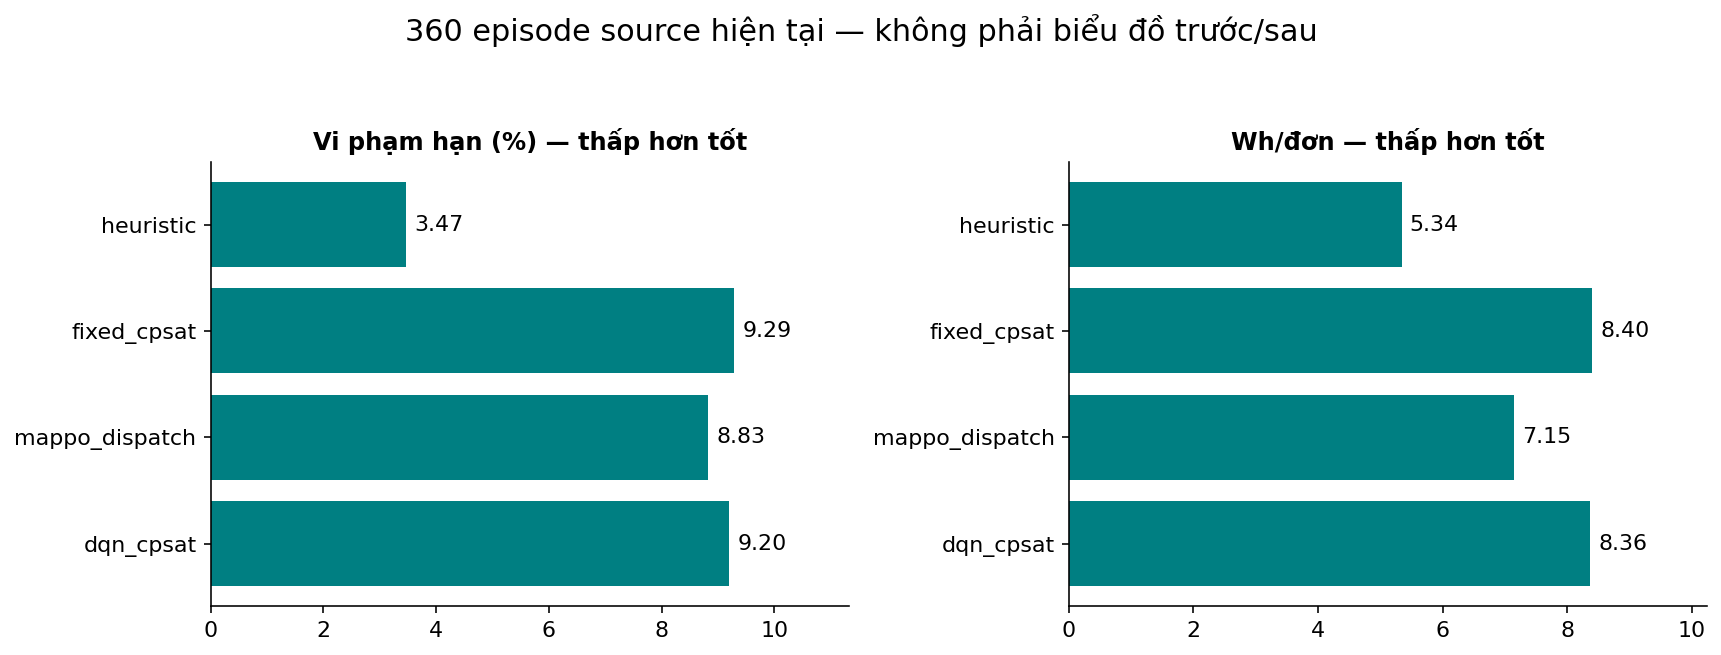

In [16]:
identity = read_json('runs/study14_current_source_testonly/identity.json')
status = read_json('runs/study14_current_source_testonly/status.json')
recent_rows = read_csv('runs/study14_current_source_testonly/episodes.csv')
recent = []
for method in ['heuristic', 'fixed_cpsat', 'mappo_dispatch', 'dqn_cpsat']:
    subset = [r for r in recent_rows if r['method'] == method]
    means = {k: mean(float(r[k]) for r in subset) for k in
             ['completion_rate', 'deadline_violation_rate', 'consumed_wh',
              'energy_per_completed_wh', 'online_decision_p95_ms']}
    recent.append({'method': method, 'n': len(subset), **means})
print('Trạng thái artifact:', status)
print('Số episode CSV:', len(recent_rows))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, metric, factor, title in [
    (axes[0], 'deadline_violation_rate', 100, 'Vi phạm hạn (%) — thấp hơn tốt'),
    (axes[1], 'energy_per_completed_wh', 1, 'Wh/đơn — thấp hơn tốt')]:
    values = [r[metric] * factor for r in recent]
    bars = ax.barh([r['method'] for r in recent], values, color=AFTER)
    ax.bar_label(bars, fmt='%.2f', padding=4)
    ax.set_xlim(0, max(values) * 1.22)
    ax.invert_yaxis()
    ax.set_title(title, fontsize=12)
fig.suptitle('360 episode source hiện tại — không phải biểu đồ trước/sau', fontsize=15)
fig.tight_layout(rect=(0, 0, 1, .93))

| Phương pháp | Episode | Hoàn thành (%) | Vi phạm hạn (%) | Wh/đơn | TB p95 (ms) |
| --- | --- | --- | --- | --- | --- |
| heuristic | 45 | 98.42 | 3.47 | 5.34 | 8.83 |
| fixed_cpsat | 45 | 98.23 | 9.29 | 8.40 | 11.34 |
| mappo_dispatch | 135 | 97.69 | 8.83 | 7.15 | 9.39 |
| dqn_cpsat | 135 | 98.23 | 9.20 | 8.36 | 12.67 |

## 9. Kết luận và vấn đề còn tồn tại

| Lỗi / vấn đề | Mức cải thiện đã quan sát | Giới hạn còn lại |
|---|---|---|
| Dao động parking không có đơn | Đường đi rảnh Fixed 1.553 → 0 m; MAPPO 694 → 0 m; đúng 20 Wh phụ tải | Không chứng minh mọi workload giảm điện; có hồi quy pending ở bản parking đầu |
| Nhận task khi đang đi đỗ | Nhóm A qua gate đã khai báo; Fixed/MAPPO giảm Wh ở S2/S4/S6 | Một số completion/trễ hạn xấu đi; 5 seed/nhóm còn ít |
| Nút thắt sạc | S6/heuristic/1001 hoàn thành 17 → 32 đơn | Source cuối vẫn có calendar chặn phục vụ ở ca khác |
| Pause | Ba controller nhận task ở giây 5 và hoàn thành 1/1 sau sửa | Không đủ bảng KPI trước/sau cho cả ba |
| Dữ liệu trễ | Ca delay15 hoàn thành 8 → 62 đơn | 357/360 chu kỳ dựa vào telemetry vật lý mới qua fallback |
| Chu kỳ endpoint | Fixture 0/2 → 2/2 task, safety 2 → 0, xử lý 2 deadlock | 40 ca S4 trước không tái hiện safety; Fixed sau có tăng tổng trễ |
| Khả năng phục vụ hiện tại | 300 ca không học và 360 transfer đã hoàn tất | Hoàn tất không đồng nghĩa nghiệm thu toàn bộ |

**Ca âm phải giữ:** bộ 300 trên source cuối có S6/Fixed/3005 chỉ hoàn thành
**17/39 = 43,59%**, còn 22 đơn trong 1.200 s. Ca này dưới gate 50%, safety = 0.
Snapshot chỉ ra lịch sạc chặn ứng viên; chưa chứng minh nguyên nhân duy nhất hay cách sửa hoàn chỉnh.
Bộ 300 có **100 ca đủ gate, 199 chưa đủ bằng chứng, 1 không đạt**;
200 ca CP-SAT/MPC thiếu timeout (gồm cả ca không đạt).
Sáu deadlock trong bộ này đều được xử lý, không mất task hoặc crash được báo cáo.

**Không có một con số “cải thiện toàn dự án X%” đáng tin cậy từ các tập này.**
Nên báo cáo theo lỗi và cặp điều kiện cụ thể. Lượt 360 dùng tape đã quan sát,
chưa phải xác nhận trên dữ liệu hoàn toàn mới; chưa train lại learner.

## 10. Nguồn, dấu vân tay dữ liệu và khả năng tái lập

Ô dưới chỉ đọc bytes và tính SHA-256. Dấu vân tay ghi lại file đã dùng khi tạo notebook;
không thay thế kiểm tra chất lượng source. Các path tương đối tính từ repository root.
Nếu chia sẻ notebook, bảng và hình vẫn xem được; muốn chạy lại các ô đọc dữ liệu
phải có những artifact tương ứng trong `runs/` (thư mục này thường bị Git bỏ qua).

In [17]:
extra_sources = [
    'runs/study14/plan.json', 'runs/study14/source_migration.json',
    'runs/readiness_nonlearning_fresh_20261013/FINAL_REPORT.md',
    'runs/paused_candidate_20261013/FIX_VERIFICATION.json',
    'runs/charging_access_20261013/CHARGING_FIX.md',
    'runs/stale_fallback_20261013/FIX_VERIFICATION.json',
    'runs/endpoint_wait_fix_20261013/FIX_REPORT.md',
]
for relative in extra_sources:
    path = ROOT / relative
    if not path.is_file():
        raise FileNotFoundError(path)
    used_files.add(path)
provenance = [{'path': p.relative_to(ROOT).as_posix(),
               'sha256': hashlib.sha256(p.read_bytes()).hexdigest()}
              for p in sorted(used_files)]
print(f'{len(provenance)} file nguồn được đọc; không chạy lại episode.')
for row in provenance:
    print(row['sha256'], row['path'])

273 file nguồn được đọc; không chạy lại episode.
17d288f4a241eb9b6e38c4053dc8593da3c8e2f7af331defa72bde16f71e400e runs/charging_access_20261013/CHARGING_FIX.md
4cf352a745630577b51a91f968d04a3b5cd8fd765f526ec3787454f574c2d881 runs/charging_access_20261013/partial_backlog_v2/pilot/S6_replay1200_heuristic_1001/manifest.json
40ae094179a1d8160c3b32f60d12497f1bd1ff087295dae56a96320c9443e388 runs/charging_access_20261013/partial_backlog_v2/pilot/S6_replay1200_heuristic_1001/metrics.json
7ce880ad2f334c731b30daac5ed1ccd496f6abc9d78ec228b59c030632dede28 runs/dispatch_regression_20261013/default_validation/baseline/S2_fixed_cpsat_1000/summary.json
faf371b6e30c7c54b20d47369f99f87eedd3f18d8807e8a604804f42deb73d47 runs/dispatch_regression_20261013/default_validation/baseline/S2_fixed_cpsat_1001/summary.json
8a645b7dbf6b3c38b64fe90203b9216234fedce2403428ab30c3b412b31f4de3 runs/dispatch_regression_20261013/default_validation/baseline/S2_fixed_cpsat_1002/summary.json
c1b1567aaf1886ae78d7e1141cf0795778c